# Fase 4: modelo

**analisis-barberias-peluquerias** · barberías de Santiago en Instagram

El objetivo es predecir `log_likes` = ln(1 + likes) de un post. Se evalúan dos escenarios, porque no es lo mismo predecir
para una barbería que ya conoces que para una nueva:

| Escenario | Pregunta | Validación |
|---|---|---|
| **A. Barbería conocida** | ¿Cuántos likes tendrá el próximo post de una cuenta de la que ya tengo historial? | **Temporal**: se entrena con el pasado y se evalúa con los posts siguientes, en 4 cortes de tiempo |
| **B. Barbería nueva** | ¿Cuántos likes tendrá un post de una cuenta que el modelo nunca vio? | **GroupKFold por cuenta**: las cuentas de prueba no aparecen en el entrenamiento |

En el escenario A se agrega la feature **`nivel_reciente`**: el promedio de log_likes de los 20 posts **anteriores** de la
misma cuenta. Solo usa el pasado de cada post, así que no filtra información del futuro.

**Métricas** (en escala log, sobre posts que el modelo no vio al entrenar):

- **MAE**: error absoluto medio. Es la principal. **error ×** = e^MAE: "en promedio se equivoca por este factor"
  (×2 = predice el doble o la mitad).
- **MAE sin virales**: sin los posts muy atípicos para su cuenta (z robusto > 3,5), que nadie podría predecir.
- **MedAE**: mediana del error absoluto. **MAE x cuenta**: promedio del MAE de cada cuenta (cada cuenta pesa lo mismo).
- **R²**: proporción de la variación explicada.

Todo el código del modelo está en `entrenar_modelo.py` y `regresion_gd.py`; este notebook los usa y muestra los resultados.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
import entrenar_modelo as em
from anonimizar import mapa_cuentas
from regresion_gd import RegresionLinealGD

warnings.simplefilter("ignore", ConvergenceWarning)
df = em.cargar(RAIZ / "data" / "posts_features.csv")

# True: en los gráficos las cuentas aparecen como "Barbería 01..19" (01 = la con más posts), igual que en el notebook 03.
# Los datos no se modifican, así que los resultados son idénticos a los de entrenar_modelo.py.
ANONIMIZAR = True
_mapa = mapa_cuentas(df["username"]) if ANONIMIZAR else {}
etiqueta = lambda usuario: _mapa.get(usuario, usuario)

GUARDAR_FIGURAS = True      # copia algunos gráficos en docs/img/ para el README
CARPETA_FIGURAS = RAIZ / "docs" / "img"


def guardar(fig, nombre):
    if GUARDAR_FIGURAS:
        CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
        fig.savefig(CARPETA_FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

AZUL, GRIS = "#2a78d6", "#8a8984"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # tres primeras series (paleta validada para daltonismo)
TINTA, TINTA_2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO, "figure.dpi": 110,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 1, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "legend.frameon": False,
})
pd.set_option("display.width", 160)
COLUMNAS = ["MAE", "error_tipico_x", "MAE_sin_virales", "MedAE", "MAE_por_cuenta", "R2"]

print(f"{len(df):,} posts de {df['username'].nunique()} cuentas, "
      f"{df['fecha_publicacion_utc'].min():%d-%m-%Y} a {df['fecha_publicacion_utc'].max():%d-%m-%Y}")

1,292 posts de 19 cuentas, 15-10-2025 a 08-10-2026


## 1. Escenario A: barbería conocida

Se comparan tres **referencias** simples contra los modelos. Si un modelo no le gana a las referencias, no aporta.

- **Mediana global**: predice siempre lo mismo.
- **Promedio histórico de la cuenta**: el promedio de todos los posts anteriores de la cuenta en el entrenamiento.
- **Nivel reciente**: el promedio de sus últimos 20 posts.

In [2]:
tabla_a, pred_a = em.evaluar_barberia_conocida(df)
print(f"Posts evaluados: {int(tabla_a['posts'].iloc[0])} (los del 50% más reciente del período, en 4 tramos)")
tabla_a[COLUMNAS + ["tipo"]].astype({c: float for c in COLUMNAS}).round(3)

Posts evaluados: 646 (los del 50% más reciente del período, en 4 tramos)


,MAE,error_tipico_x,MAE_sin_virales,MedAE,MAE_por_cuenta,R2,tipo
Huber (lineal robusta) + nivel,0.687,1.989,0.629,0.517,0.632,0.437,modelo
Nivel reciente (20 posts),0.697,2.007,0.640,0.531,0.656,0.432,referencia
Ridge + nivel,0.708,2.029,0.650,0.557,0.630,0.426,modelo
Regresión lineal (descenso de gradiente propio) + nivel,0.708,2.029,0.651,0.555,0.639,0.428,modelo
Regresión lineal + nivel,0.708,2.029,0.651,0.555,0.639,0.428,modelo
Random Forest + nivel,0.729,2.073,0.669,0.566,0.679,0.369,modelo
Promedio histórico de la cuenta,0.760,2.139,0.702,0.591,0.680,0.352,referencia
Regresión lineal sin nivel,0.929,2.533,0.870,0.766,0.822,0.119,modelo
Mediana global,0.964,2.623,0.903,0.734,1.041,-0.039,referencia


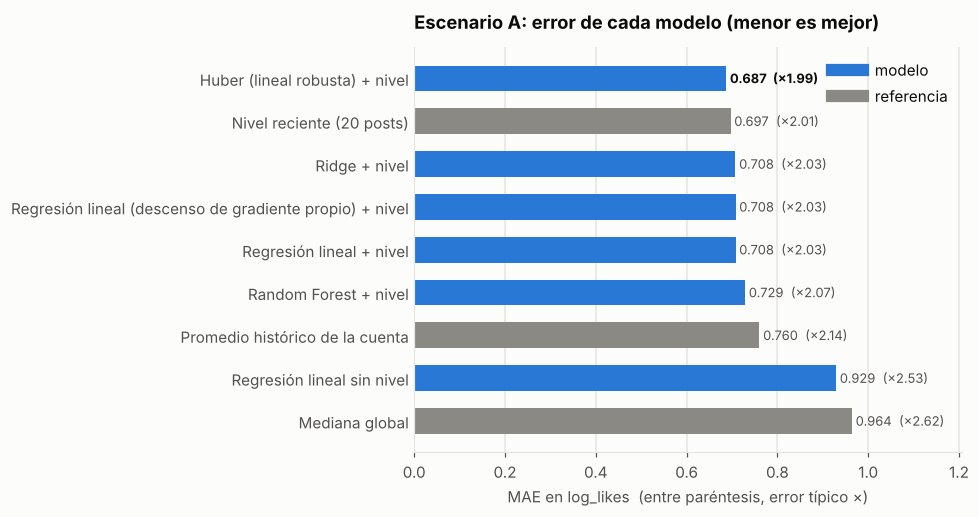

Mejor modelo: Huber (lineal robusta) + nivel
  MAE 0.687 vs 0.697 del nivel reciente → 1.3% mejor por post
  MAE por cuenta 0.632 vs 0.656 → 3.8% mejor por cuenta


In [3]:
orden = tabla_a.sort_values("MAE", ascending=False)
nombre_final = em.elegir_modelo(tabla_a) + " + nivel"

fig, ax = plt.subplots(figsize=(9, 4.8))
colores = [GRIS if t == "referencia" else AZUL for t in orden["tipo"]]
ax.barh(orden.index, orden["MAE"].astype(float), height=0.6, color=colores)
for y, (nombre, fila) in enumerate(orden.iterrows()):
    ax.text(float(fila["MAE"]) + 0.008, y, f"{float(fila['MAE']):.3f}  (×{float(fila['error_tipico_x']):.2f})",
            va="center", fontsize=8.5, color=TINTA if nombre == nombre_final else TINTA_2,
            fontweight="bold" if nombre == nombre_final else "normal")
ax.set_xlim(0, float(orden["MAE"].max()) * 1.25)
ax.set_title("Escenario A: error de cada modelo (menor es mejor)")
ax.set_xlabel("MAE en log_likes  (entre paréntesis, error típico ×)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Line2D([], [], color=AZUL, linewidth=8, label="modelo"),
                   Line2D([], [], color=GRIS, linewidth=8, label="referencia")], loc="upper right")
plt.tight_layout()
guardar(fig, "modelos_escenario_a")
plt.show()

final, nivel = tabla_a.loc[nombre_final], tabla_a.loc["Nivel reciente (20 posts)"]
print(f"Mejor modelo: {nombre_final}")
print(f"  MAE {float(final['MAE']):.3f} vs {float(nivel['MAE']):.3f} del nivel reciente "
      f"→ {(1 - float(final['MAE']) / float(nivel['MAE'])) * 100:.1f}% mejor por post")
print(f"  MAE por cuenta {float(final['MAE_por_cuenta']):.3f} vs {float(nivel['MAE_por_cuenta']):.3f} "
      f"→ {(1 - float(final['MAE_por_cuenta']) / float(nivel['MAE_por_cuenta'])) * 100:.1f}% mejor por cuenta")

**Cómo leer la tabla:**

- **El nivel reciente de la cuenta es casi todo.** Solo con el promedio de sus últimos 20 posts se logra un error típico de
  ×2, y la regresión lineal **sin** esa feature (solo con las características del post) queda cerca de la mediana global.
- **El nivel reciente le gana al promedio histórico.** Las cuentas cambian con el tiempo, así que el pasado reciente
  predice mejor que el año completo.
- **Las features del post agregan poco, pero algo.** El mejor modelo mejora apenas al nivel reciente por post, y un poco
  más al medirlo por cuenta. Es coherente con la Fase 3: los efectos de formato y llamado a la acción existen, pero
  son chicos comparados con la variación natural entre posts.
- **Huber le gana a la regresión lineal clásica.** La regresión lineal minimiza el error **al cuadrado**, así que unos
  pocos virales la tironean. Huber (una regresión lineal robusta) trata los errores grandes como lineales y no se deja
  arrastrar por ellos.
- **La regresión lineal propia (descenso de gradiente) da exactamente lo mismo que la de scikit-learn**, como debe ser.
  El detalle está en la sección 5.
- **Random Forest no ayuda.** Con 19 cuentas y relaciones casi lineales, un modelo más flexible se sobreajusta.

### Predicho vs real

Cada punto es un post evaluado fuera de muestra con el mejor modelo. Si el modelo fuera perfecto, todos estarían sobre la
diagonal.

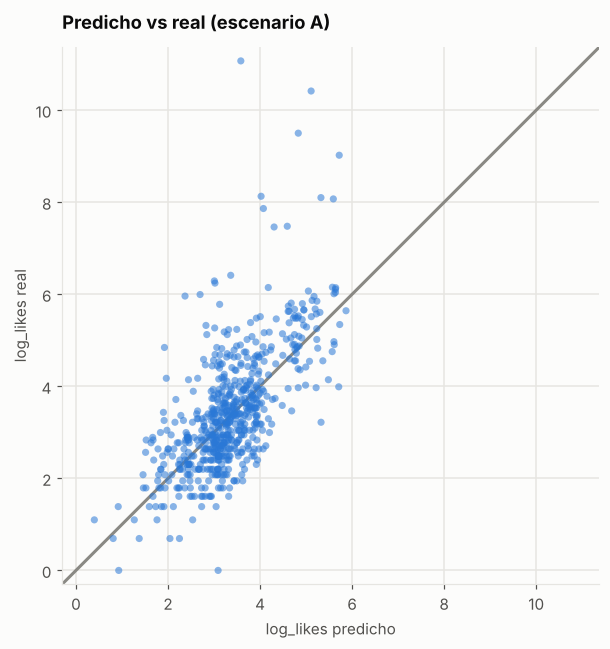

Rango predicho: 0.4 a 5.9 | rango real: 0.0 a 11.1


In [4]:
real, predicho = pred_a["log_likes"], pred_a[nombre_final]
fig, ax = plt.subplots(figsize=(6.2, 6))
limite = [min(real.min(), predicho.min()) - 0.3, max(real.max(), predicho.max()) + 0.3]
ax.plot(limite, limite, color=GRIS, linewidth=2, zorder=1)
ax.scatter(predicho, real, s=22, color=AZUL, alpha=0.55, edgecolor="none", zorder=2)
ax.set_xlim(limite)
ax.set_ylim(limite)
ax.set_aspect("equal")
ax.set_title("Predicho vs real (escenario A)")
ax.set_xlabel("log_likes predicho")
ax.set_ylabel("log_likes real")
plt.tight_layout()
guardar(fig, "predicho_vs_real")
plt.show()

print(f"Rango predicho: {predicho.min():.1f} a {predicho.max():.1f} | rango real: {real.min():.1f} a {real.max():.1f}")

Las predicciones se concentran en un rango mucho más angosto que los valores reales: el modelo predice bien "el nivel
normal" de cada cuenta, pero no anticipa qué post va a explotar ni cuál va a pasar desapercibido. Los puntos muy por
encima de la diagonal son los virales.

### Error por cuenta

¿En qué cuentas ayudan las features del post? Se compara el error del mejor modelo con el del nivel reciente.

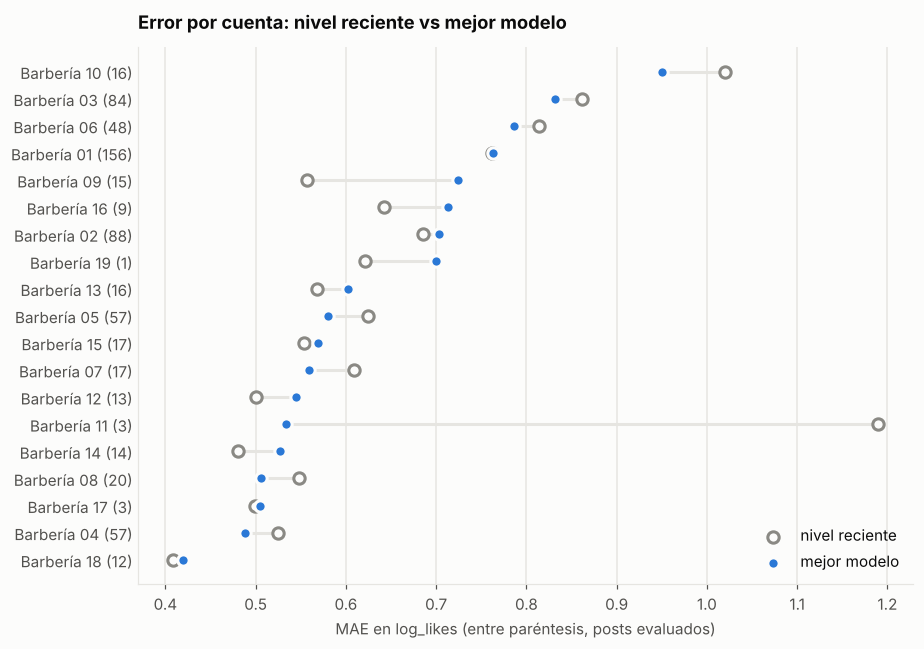

Mejor modelo vs nivel reciente, cuenta por cuenta (19 cuentas):
  gana (al menos 0,01 menos de MAE): 8 → Barbería 04 (57), Barbería 08 (20), Barbería 11 (3), Barbería 07 (17), Barbería 05 (57), Barbería 06 (48), Barbería 03 (84), Barbería 10 (16)
  empata: 2 → Barbería 17 (3), Barbería 01 (156)
  pierde (al menos 0,01 más de MAE): 9 → Barbería 18 (12), Barbería 14 (14), Barbería 12 (13), Barbería 15 (17), Barbería 13 (16), Barbería 19 (1), Barbería 02 (88), Barbería 16 (9), Barbería 09 (15)


In [5]:
error = pd.DataFrame({
    "nivel reciente": (pred_a["log_likes"] - pred_a["Nivel reciente (20 posts)"]).abs(),
    "mejor modelo": (pred_a["log_likes"] - pred_a[nombre_final]).abs(),
    "username": pred_a["username"],
}).groupby("username").agg(posts=("mejor modelo", "size"), nivel=("nivel reciente", "mean"),
                           modelo=("mejor modelo", "mean")).sort_values("modelo")

fig, ax = plt.subplots(figsize=(8.5, 6))
for y, (cuenta, fila) in enumerate(error.iterrows()):
    ax.plot([fila["nivel"], fila["modelo"]], [y, y], color=GRILLA, linewidth=2, zorder=1)
ax.scatter(error["nivel"], range(len(error)), s=55, color=FONDO, edgecolor=GRIS, linewidth=2, zorder=2, label="nivel reciente")
ax.scatter(error["modelo"], range(len(error)), s=55, color=AZUL, edgecolor=FONDO, linewidth=2, zorder=3, label="mejor modelo")
ax.set_yticks(range(len(error)), [f"{etiqueta(c)} ({n})" for c, n in error["posts"].items()])
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE en log_likes (entre paréntesis, posts evaluados)")
ax.set_title("Error por cuenta: nivel reciente vs mejor modelo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

dif = error["modelo"] - error["nivel"]
grupos = {"gana (al menos 0,01 menos de MAE)": dif <= -0.01, "empata": dif.abs() < 0.01,
          "pierde (al menos 0,01 más de MAE)": dif >= 0.01}
print(f"Mejor modelo vs nivel reciente, cuenta por cuenta ({len(error)} cuentas):")
for texto, mascara in grupos.items():
    print(f"  {texto}: {mascara.sum()} → " + ", ".join(f"{etiqueta(c)} ({n})" for c, n in error.loc[mascara, "posts"].items()))

La mejora **no es pareja**. El modelo gana en 8 de las 19 cuentas, entre ellas cuatro de las seis con más posts evaluados
(Barbería 03, 04, 05 y 06). Empata en Barbería 01, la que más publica, y pierde en Barbería 02 y en varias cuentas con
pocos posts evaluados. Las cuentas con 1 a 3 posts evaluados tienen un error demasiado ruidoso para sacar conclusiones.
En resumen, las features del post ayudan algo en promedio, pero no de forma consistente en todas las barberías.

## 2. Escenario B: barbería nueva

Aquí el modelo no tiene historial de la cuenta: solo sabe sus seguidores y las características del post.

In [6]:
tabla_b = em.evaluar_barberia_nueva(df)
tabla_b[COLUMNAS + ["tipo"]].astype({c: float for c in COLUMNAS}).round(3)

,MAE,error_tipico_x,MAE_sin_virales,MedAE,MAE_por_cuenta,R2,tipo
Mediana global,0.982,2.669,0.915,0.722,1.136,-0.067,referencia
Solo seguidores,0.991,2.695,0.926,0.788,0.932,-0.019,referencia
Huber (lineal robusta),1.038,2.824,0.974,0.858,0.972,-0.073,modelo
Ridge,1.058,2.882,0.996,0.883,0.969,-0.101,modelo
Regresión lineal,1.064,2.899,1.003,0.890,0.975,-0.110,modelo
Random Forest,1.166,3.211,1.105,0.937,1.107,-0.329,modelo


Sin historial, **ningún modelo le gana a la mediana global en error por post**, y el R² queda en torno a cero o negativo.
Medido por cuenta, usar solo los seguidores es lo que mejor funciona: ajusta el nivel según el tamaño de la cuenta, pero el
error típico sigue siendo de casi ×3.

La conclusión es clara: **con datos públicos, el rendimiento de una barbería que no conoces es muy difícil de anticipar**.
Lo que más pesa es el "estilo" propio de cada cuenta (su comunidad, su tipo de contenido), y eso solo se ve con historial.
Por eso el modelo final es el del escenario A.

## 3. Decisiones probadas

Dos decisiones de la Fase 3 se pusieron a prueba con la misma validación temporal.

In [7]:
def validar_temporal(nombre_modelo, con_pesos=False, ventana=20):
    y = df["log_likes"].to_numpy()
    X_post, previo = em.matriz_features(df), em.nivel_previo(df, ventana)
    pred = np.full(len(df), np.nan)
    for inicio, fin in em.cortes_temporales(df["fecha_publicacion_utc"]):
        tr = (df["fecha_publicacion_utc"] < inicio).to_numpy()
        te = ((df["fecha_publicacion_utc"] >= inicio) & (df["fecha_publicacion_utc"] < fin)).to_numpy()
        X = X_post.assign(nivel_reciente=previo.fillna(y[tr].mean()))
        usuarios = df.loc[tr, "username"]
        pesos = (len(usuarios) / usuarios.nunique()) / usuarios.map(usuarios.value_counts())
        modelo = em.catalogo_modelos()[nombre_modelo]()
        modelo.fit(X[tr], y[tr], **({"modelo__sample_weight": pesos.to_numpy()} if con_pesos else {}))
        pred[te] = modelo.predict(X[te])
    ok = ~np.isnan(pred)
    return em.metricas(y[ok], pred[ok], df.loc[ok, "username"], em.marcar_virales(df)[ok])


experimentos = {}
for nombre in ["Huber (lineal robusta)", "Ridge"]:
    experimentos[(nombre, "sin pesos")] = validar_temporal(nombre)
    experimentos[(nombre, "con peso_cuenta")] = validar_temporal(nombre, con_pesos=True)
print("¿Sirve dar el mismo peso a cada cuenta al entrenar (peso_cuenta de la Fase 2)?")
pd.DataFrame(experimentos).T[["MAE", "MAE_por_cuenta", "R2"]].astype(float).round(3)

¿Sirve dar el mismo peso a cada cuenta al entrenar (peso_cuenta de la Fase 2)?


MAE  MAE_por_cuenta     R2
Huber (lineal robusta) sin pesos        0.687           0.632  0.437
                       con peso_cuenta  0.695           0.623  0.438
Ridge                  sin pesos        0.708           0.630  0.426
                       con peso_cuenta  0.706           0.616  0.432

In [8]:
ventanas = {}
for v in [5, 10, 20, 40]:
    t, _ = em.evaluar_barberia_conocida(df, ventana=v)
    ventanas[v] = {"MAE nivel reciente": float(t.loc[f"Nivel reciente ({v} posts)", "MAE"]),
                   "MAE Huber + nivel": float(t.loc["Huber (lineal robusta) + nivel", "MAE"])}
print("¿Cuántos posts anteriores usar para el nivel reciente?")
pd.DataFrame(ventanas).T.rename_axis("ventana").round(3)

¿Cuántos posts anteriores usar para el nivel reciente?


,MAE nivel reciente,MAE Huber + nivel
ventana,,
5,0.733,0.696
10,0.702,0.677
20,0.697,0.687
40,0.706,0.708


- **Pesos por cuenta:** con pesos mejora un poco el error por cuenta y empeora un poco el error por post. La diferencia es
  chica en ambos sentidos, así que se entrena **sin pesos**, que es más simple. La métrica "MAE x cuenta" ya muestra cómo
  le va a cada cuenta por igual.
- **Ventana del nivel reciente:** con muy pocos posts el promedio es ruidoso, y con muchos se vuelve lento para seguir los
  cambios de la cuenta. El nivel reciente solo funciona mejor con 20; el modelo completo queda levemente mejor con 10. Pero
  elegir la ventana mirando estos mismos resultados es una forma de sobreajustar la validación, y la diferencia es chica.
  Se deja 20 (`--ventana` en el script, si quieres probar otra).

## 4. Modelo final

El script elige automáticamente el modelo con menor MAE en el escenario A, lo entrena con **todos** los posts y lo guarda
en `modelos/modelo_final.joblib`, con sus métricas en `modelos/modelo_final.json`.

Coeficientes del modelo final en escala original. `efecto_%` es el cambio estimado en likes ante el cambio de la columna
`lectura`, **manteniendo fijo el nivel reciente de la cuenta y todo lo demás**. La interpretación detallada es parte de la
Fase 5.

In [9]:
nombre_modelo = em.elegir_modelo(tabla_a)
modelo_final, columnas, _ = em.entrenar_final(df, nombre_modelo)
coefs = em.coeficientes(modelo_final, columnas)
print(f"Modelo final: {nombre_modelo} + nivel, entrenado con {len(df)} posts")
coefs[["variable", "lectura", "coef_original", "efecto_%"]].round(3) if coefs is not None else "El modelo no es lineal"

Modelo final: Huber (lineal robusta) + nivel, entrenado con 1292 posts


,variable,lectura,coef_original,efecto_%
0,nivel_reciente,"+0,1 en el log_likes promedio reciente de la c...",0.804,8.372
1,es_reel,reel en vez de imagen,0.500,64.805
2,es_carrusel,carrusel en vez de imagen,0.325,38.349
3,log_seguidores,el doble de seguidores,0.141,10.294
4,tiene_llamado_accion,tiene llamado a la acción,-0.242,-21.485
5,log_largo_texto,el doble de largo de texto propio,0.074,5.245
6,log_emojis,el doble de emojis propios,0.106,7.652
7,log_hashtags,el doble de hashtags propios,-0.075,-5.075
8,menciona_precio_promo,menciona precio o promoción,-0.351,-29.576
9,posts_ultimos_7_dias,un post más en los 7 días previos,-0.010,-0.953


## 5. Regresión lineal con descenso de gradiente propio

`regresion_gd.py` implementa la regresión lineal desde cero. Minimiza el error cuadrático medio

$$J(\beta, b) = \frac{1}{n}\sum_{i=1}^{n} \left(y_i - x_i \cdot \beta - b\right)^2$$

y en cada iteración da un paso en contra del gradiente:

$$\beta \leftarrow \beta - \eta \cdot \frac{-2}{n} X^\top r \qquad b \leftarrow b - \eta \cdot \frac{-2}{n} \sum r_i \qquad r = y - X\beta - b$$

donde $\eta$ es la tasa de aprendizaje. Se compara contra `LinearRegression` de scikit-learn, que resuelve el mismo
problema de forma exacta (mínimos cuadrados).

In [10]:
y = df["log_likes"].to_numpy()
X = em.matriz_features(df).assign(nivel_reciente=em.nivel_previo(df).fillna(y.mean()))
X_est = StandardScaler().fit_transform(X)        # el descenso de gradiente necesita features en la misma escala

propia = RegresionLinealGD(tasa_aprendizaje=0.1).fit(X_est, y)
sklearn_lr = LinearRegression().fit(X_est, y)

comparacion = pd.DataFrame({"descenso de gradiente": propia.coef_, "scikit-learn": sklearn_lr.coef_}, index=X.columns)
comparacion.loc["(intercepto)"] = [propia.intercept_, sklearn_lr.intercept_]
comparacion["diferencia"] = (comparacion["descenso de gradiente"] - comparacion["scikit-learn"]).abs()
print(f"Iteraciones: {propia.n_iter_} | convergió: {propia.convergio_} | "
      f"diferencia máxima: {comparacion['diferencia'].max():.1e}")
comparacion.round(6)

Iteraciones: 200 | convergió: True | diferencia máxima: 4.1e-06


,descenso de gradiente,scikit-learn,diferencia
log_seguidores,0.155827,0.155829,0.000002
es_reel,0.252193,0.252197,0.000004
es_carrusel,0.170057,0.170061,0.000004
tiene_llamado_accion,-0.164972,-0.164973,0.000000
menciona_precio_promo,-0.023779,-0.023779,0.000000
tiene_pregunta,-0.009690,-0.009691,0.000000
es_fin_de_semana,0.020445,0.020445,0.000000
franja_tarde,0.049404,0.049404,0.000000
franja_noche,0.003724,0.003724,0.000000
franja_madrugada,0.025466,0.025467,0.000000


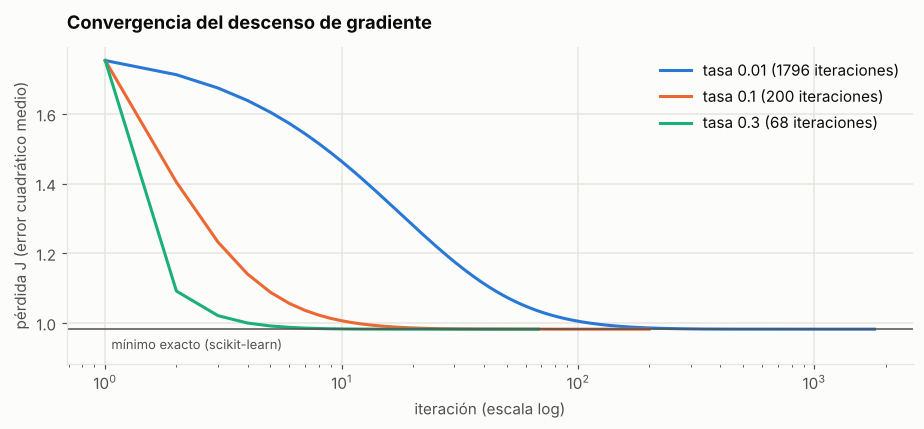

Para que converja, la tasa tiene que ser menor que 2 / 4.75 = 0.42


In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for color, tasa in zip(SERIES, [0.01, 0.1, 0.3]):
    modelo = RegresionLinealGD(tasa_aprendizaje=tasa).fit(X_est, y)
    historial = modelo.historial_perdida_
    ax.plot(np.arange(1, len(historial) + 1), historial, color=color, linewidth=2,
            label=f"tasa {tasa} ({modelo.n_iter_} iteraciones)")
minimo = np.mean((y - sklearn_lr.predict(X_est)) ** 2)
ax.axhline(minimo, color=TINTA_2, linewidth=1)
ax.annotate("mínimo exacto (scikit-learn)", (1, minimo), xytext=(4, -13), textcoords="offset points",
            fontsize=8.5, color=TINTA_2)
ax.set_ylim(bottom=minimo - 0.1)
ax.set_xscale("log")
ax.set_title("Convergencia del descenso de gradiente")
ax.set_xlabel("iteración (escala log)")
ax.set_ylabel("pérdida J (error cuadrático medio)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

autovalor_max = np.linalg.eigvalsh(2 * X_est.T @ X_est / len(y)).max()
print(f"Para que converja, la tasa tiene que ser menor que 2 / {autovalor_max:.2f} = {2 / autovalor_max:.2f}")

Con una tasa chica avanza lento; con una más grande llega en menos iteraciones. Pero hay un límite: si la tasa supera
2 / (el mayor autovalor de la matriz de segundas derivadas), cada paso se pasa del mínimo y la pérdida crece. En ese caso
`RegresionLinealGD` se detiene con un error en vez de devolver basura. Estandarizar las features es lo que hace que una
misma tasa sirva para todas.

## 6. Conclusiones

1. **Lo que mejor predice los likes de un post es el rendimiento reciente de su cuenta.** El promedio de los últimos 20 posts
   ya da un error típico de ×2, y le gana al promedio histórico porque las cuentas cambian con el tiempo.
2. **Las features del post aportan poco.** El mejor modelo (Huber + nivel reciente) mejora al nivel reciente en ~1% por
   post y ~4% por cuenta, y cuenta por cuenta gana solo en 8 de las 19. Los coeficientes de formato y llamado a la
   acción van en la misma dirección que en la Fase 3, pero esos efectos son chicos al lado de lo impredecible que es
   cada post.
3. **Una regresión robusta funciona mejor que la clásica** porque los virales distorsionan el error cuadrático.
4. **Para una barbería nueva, sin historial, no se puede predecir mucho mejor que con la mediana.** El tamaño de la cuenta
   ayuda algo, pero el error típico se acerca a ×3.
5. **La regresión con descenso de gradiente propio llega a los mismos coeficientes que scikit-learn.**

Un modelo con R² cercano a 0,44 y error típico ×2 no es un mal resultado con datos públicos de Instagram: lo honesto es
mostrar cuánto se puede predecir, qué no, y por qué.

**Para la Fase 5:** `data/coeficientes_modelo.csv` (efectos de cada variable), `data/predicciones_validacion.csv`
(predicciones fuera de muestra) y `data/resultados_modelos.csv` (comparación de modelos) son la base del dashboard y del
README final.